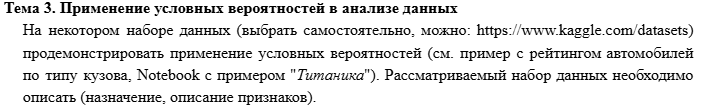

> Из набора Wine случайно и равновероятно выбирается одна строка. Найти вероятность того, что образец относится к классу 0: без дополнительной информации, при условии содержания алкоголя не менее 13,5% и при противоположном условии. Сравнить прямой подсчёт с формулой Байеса, проверить формулу полной вероятности и рассмотреть зависимость событий.

In [8]:
import numpy as np
import pandas as pd

from sklearn.datasets import load_wine
from IPython.display import display

pd.options.display.float_format = "{:.3f}".format

wine = load_wine(as_frame=True)
df = wine.frame.copy()

print("Число строк и столбцов:", df.shape)
print("Пропуски по столбцам:", df.isna().sum().to_dict())
print(
    "Число наблюдений по классам:",
    df["target"].value_counts().sort_index().to_dict()
)

display(df.head())

Число строк и столбцов: (178, 14)
Пропуски по столбцам: {'alcohol': 0, 'malic_acid': 0, 'ash': 0, 'alcalinity_of_ash': 0, 'magnesium': 0, 'total_phenols': 0, 'flavanoids': 0, 'nonflavanoid_phenols': 0, 'proanthocyanins': 0, 'color_intensity': 0, 'hue': 0, 'od280/od315_of_diluted_wines': 0, 'proline': 0, 'target': 0}
Число наблюдений по классам: {0: 59, 1: 71, 2: 48}


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.230,1.710,2.430,15.600,127.000,2.800,3.060,0.280,2.290,5.640,1.040,3.920,1065.000,0
1,13.200,1.780,2.140,11.200,100.000,2.650,2.760,0.260,1.280,4.380,1.050,3.400,1050.000,0
2,13.160,2.360,2.670,18.600,101.000,2.800,3.240,0.300,2.810,5.680,1.030,3.170,1185.000,0
3,14.370,1.950,2.500,16.800,113.000,3.850,3.490,0.240,2.180,7.800,0.860,3.450,1480.000,0
4,13.240,2.590,2.870,21.000,118.000,2.800,2.690,0.390,1.820,4.320,1.040,2.930,735.000,0


### 1. Описание набора данных

Используется набор **Wine**, содержащий результаты химического анализа
178 образцов вина трёх классов. Назначение набора — определение класса
вина по его химическим характеристикам.

В наборе 13 числовых признаков: содержание алкоголя, яблочной кислоты,
зольность, щёлочность золы, содержание магния, фенольных соединений,
флавоноидов, нефлавоноидных фенолов, проантоцианидинов, интенсивность
окраски, цветовой оттенок, отношение оптических плотностей OD280/OD315
и содержание пролина.

Целевая переменная `target` обозначает класс вина: 0, 1 или 2.
В расчётах используются `alcohol` — содержание алкоголя в процентах
и `target` — класс образца. Пропущенных значений нет.

### 2. События и таблица частот

Обозначим:

- $A=\{\text{образец относится к классу 0}\}$;
- $B=\{\text{содержание алкоголя}\geq 13{,}5\%\}$;
- $\overline{B}=\{\text{содержание алкоголя}<13{,}5\%\}$.

Порог 13,5% выбран для демонстрации расчётов.

Условная вероятность определяется формулой:

$$
P(A\mid B)=\frac{P(A\cap B)}{P(B)}, \qquad P(B)>0.
$$

При случайном равновероятном выборе строки:

$$
P(A\mid B)=\frac{n(A\cap B)}{n(B)},
$$

где $n(B)$ — количество образцов, удовлетворяющих условию $B$,
а $n(A\cap B)$ — количество образцов, удовлетворяющих обоим условиям.

Знаменатель — число строк, удовлетворяющих условию, а не объём всего набора.

Составим таблицу частот.

In [9]:
A = df["target"].eq(0)
B = df["alcohol"].ge(13.5)

counts = pd.crosstab(df["target"], B).reindex(
    index=[0, 1, 2],
    columns=[False, True],
    fill_value=0
)

counts.index.name = "Класс вина"
counts.columns = ["Алкоголь < 13,5%", "Алкоголь ≥ 13,5%"]

counts["Всего"] = counts.sum(axis=1)
counts.loc["Всего"] = counts.sum(axis=0)

display(counts)

,"Алкоголь < 13,5%","Алкоголь ≥ 13,5%",Всего
Класс вина,,,
0,17,42,59
1,69,2,71
2,35,13,48
Всего,121,57,178


### 3. Безусловная, совместная и условные вероятности

Вычислим:

- $P(A)$ — вероятность выбора образца класса 0;
- $P(B)$ — вероятность содержания алкоголя не менее 13,5%;
- $P(A\cap B)$ — вероятность одновременного выполнения обоих условий;
- $P(A\mid B)$ — вероятность класса 0 при содержании алкоголя не менее 13,5%;
- $P(B\mid A)$ — вероятность содержания алкоголя не менее 13,5% среди образцов класса 0;
- $P(A\mid\overline{B})$ — вероятность класса 0 при содержании алкоголя менее 13,5%.

Безусловные и совместная вероятности:

$$
P(A)=\frac{n(A)}{N}, \qquad
P(B)=\frac{n(B)}{N}, \qquad
P(A\cap B)=\frac{n(A\cap B)}{N}.
$$

Условные вероятности:

$$
P(A\mid B)=\frac{n(A\cap B)}{n(B)},
$$

$$
P(B\mid A)=\frac{n(A\cap B)}{n(A)},
$$

$$
P(A\mid\overline{B})=
\frac{n(A\cap\overline{B})}{n(\overline{B})}.
$$

In [10]:
N = len(df)

n_A = int(A.sum())
n_B = int(B.sum())
n_AB = int((A & B).sum())
n_not_B = int((~B).sum())
n_A_not_B = int((A & ~B).sum())

p_A = n_A / N
p_B = n_B / N
p_not_B = n_not_B / N
p_AB = n_AB / N

p_A_given_B = n_AB / n_B
p_B_given_A = n_AB / n_A
p_A_given_not_B = n_A_not_B / n_not_B

result = pd.DataFrame(
    [
        ["P(A)", n_A, N, p_A],
        ["P(B)", n_B, N, p_B],
        ["P(A ∩ B)", n_AB, N, p_AB],
        ["P(A | B)", n_AB, n_B, p_A_given_B],
        ["P(B | A)", n_AB, n_A, p_B_given_A],
        ["P(A | не B)", n_A_not_B, n_not_B, p_A_given_not_B]
    ],
    columns=["Вероятность", "Числитель", "Знаменатель", "Значение"]
)

display(result)

,Вероятность,Числитель,Знаменатель,Значение
0,P(A),59,178,0.331
1,P(B),57,178,0.320
2,P(A ∩ B),42,178,0.236
3,P(A | B),42,57,0.737
4,P(B | A),42,59,0.712
5,P(A | не B),17,121,0.140


Получаем:

- $P(A)=59/178\approx 0{,}331$ — исходная вероятность класса 0.
- $P(A\mid B)=42/57\approx 0{,}737$ — вероятность класса 0 среди образцов с содержанием алкоголя не менее 13,5%.
- $P(B\mid A)=42/59\approx 0{,}712$ — вероятность содержания алкоголя не менее 13,5% среди образцов класса 0.
- $P(A\mid\overline{B})=17/121\approx 0{,}140$ — вероятность класса 0 среди образцов с содержанием алкоголя менее 13,5%.

Таким образом, информация о содержании алкоголя изменяет вероятность
принадлежности образца к классу 0.

Вероятности $P(A\mid B)$ и $P(B\mid A)$ имеют разный смысл:
они рассчитываются относительно разных групп образцов.

### 4. Условные вероятности для всех классов

Сначала нормируем таблицу частот по строкам: получаем вероятности диапазонов
содержания алкоголя при известном классе.

Затем нормируем таблицу по столбцам: получаем вероятности классов
при известном диапазоне содержания алкоголя.

В первой таблице сумма вероятностей в каждой строке равна 1.
Во второй таблице сумма вероятностей в каждом столбце равна 1.

Суммы отображаемых округлённых значений могут незначительно отличаться от 1.

In [11]:
by_class = pd.crosstab(
    df["target"],
    B,
    normalize="index"
).reindex(
    index=[0, 1, 2],
    columns=[False, True],
    fill_value=0
)

by_class.index.name = "Класс вина"
by_class.columns = [
    "P(алкоголь < 13,5% | класс)",
    "P(алкоголь ≥ 13,5% | класс)"
]

print("Условие — класс вина; каждая строка суммируется в 1:")
display(by_class)

by_alcohol = pd.crosstab(
    df["target"],
    B,
    normalize="columns"
).reindex(
    index=[0, 1, 2],
    columns=[False, True],
    fill_value=0
)

by_alcohol.index.name = "Класс вина"
by_alcohol.columns = [
    "P(класс | алкоголь < 13,5%)",
    "P(класс | алкоголь ≥ 13,5%)"
]

print("Условие — содержание алкоголя; каждый столбец суммируется в 1:")
display(by_alcohol)

Условие — класс вина; каждая строка суммируется в 1:


,"P(алкоголь < 13,5% | класс)","P(алкоголь ≥ 13,5% | класс)"
Класс вина,,
0,0.288,0.712
1,0.972,0.028
2,0.729,0.271


Условие — содержание алкоголя; каждый столбец суммируется в 1:


,"P(класс | алкоголь < 13,5%)","P(класс | алкоголь ≥ 13,5%)"
Класс вина,,
0,0.140,0.737
1,0.570,0.035
2,0.289,0.228


### 5. Проверка формулы Байеса

По формуле Байеса:

$$
P(A\mid B)=\frac{P(B\mid A)P(A)}{P(B)}.
$$

Подставим значения:

$$
P(A\mid B)=
\frac{\frac{42}{59}\cdot\frac{59}{178}}{\frac{57}{178}}
=
\frac{42}{57}
\approx 0{,}737.
$$

Сравним результат с прямым подсчётом.
Вычисления выполняются без предварительного округления.

In [12]:
p_bayes = p_B_given_A * p_A / p_B

print(f"По формуле Байеса: {p_bayes:.3f}")
print(f"Прямым подсчётом:  {p_A_given_B:.3f}")
print("Результаты совпадают:", np.isclose(p_bayes, p_A_given_B))

По формуле Байеса: 0.737
Прямым подсчётом:  0.737
Результаты совпадают: True


### 6. Формула полной вероятности и зависимость событий

События $B$ и $\overline{B}$ несовместны и образуют полную группу событий.
Поэтому:

$$
P(A)=P(A\mid B)P(B)+P(A\mid\overline{B})P(\overline{B}).
$$

Для рассматриваемых данных:

$$
P(A)=
\frac{42}{57}\cdot\frac{57}{178}
+
\frac{17}{121}\cdot\frac{121}{178}
=
\frac{59}{178}
\approx 0{,}331.
$$

Независимость событий означала бы:

$$
P(A\cap B)=P(A)P(B).
$$

Сравним эти величины.

In [13]:
p_total = (
    p_A_given_B * p_B
    + p_A_given_not_B * p_not_B
)

print(f"По формуле полной вероятности: {p_total:.3f}")
print(f"Прямое значение P(A):          {p_A:.3f}")
print("Результаты совпадают:", np.isclose(p_total, p_A))

print(f"\nP(A ∩ B) = {p_AB:.3f}")
print(f"P(A)P(B) = {p_A * p_B:.3f}")

# Точное сравнение с помощью целочисленных частот:
# n(A ∩ B) / N = n(A)n(B) / N².
independent = n_AB * N == n_A * n_B

if independent:
    print("События A и B независимы на данном наборе данных.")
else:
    print("События A и B зависимы на данном наборе данных.")

По формуле полной вероятности: 0.331
Прямое значение P(A):          0.331
Результаты совпадают: True

P(A ∩ B) = 0.236
P(A)P(B) = 0.106
События A и B зависимы на данном наборе данных.


### 7. Визуальное сравнение

Сравним вероятности принадлежности образца к каждому классу:

- без дополнительной информации;
- при содержании алкоголя не менее 13,5%;
- при содержании алкоголя менее 13,5%.

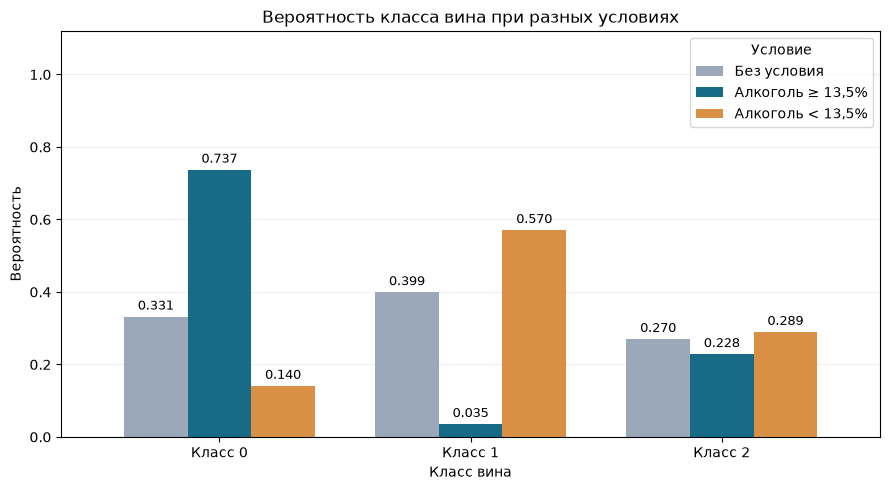

In [14]:
import matplotlib.pyplot as plt

classes = [0, 1, 2]

comparison = pd.DataFrame({
    "Без условия": (
        df["target"]
        .value_counts(normalize=True)
        .reindex(classes, fill_value=0)
    ),
    "Алкоголь ≥ 13,5%": (
        df.loc[B, "target"]
        .value_counts(normalize=True)
        .reindex(classes, fill_value=0)
    ),
    "Алкоголь < 13,5%": (
        df.loc[~B, "target"]
        .value_counts(normalize=True)
        .reindex(classes, fill_value=0)
    )
})

comparison.index = ["Класс 0", "Класс 1", "Класс 2"]

fig, ax = plt.subplots(figsize=(9, 5))

comparison.plot.bar(
    ax=ax,
    color=["#9AA8BA", "#176B87", "#D99045"],
    width=0.76
)

ax.set(
    title="Вероятность класса вина при разных условиях",
    xlabel="Класс вина",
    ylabel="Вероятность"
)

ax.set_ylim(0, 1.12)
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3,
        fontsize=9
    )

ax.legend(title="Условие", loc="upper right")

fig.tight_layout()
plt.show()